# Vereisten

1. Lever één net en duidelijk gestructureerd notebook in.
2. Structureer het notebook met markdown cellen en nummer de hoofdstukken en paragraven.
3. Gebruik markdown cellen voor tekst en code cellen voor code.
4. Gebruik zoveel mogelijk zelf-gedefinieerde functies en bij voorkeur OOP.
5. De code voldoet aan PEP8 inclusief “comments”.
6. Alle groepsgenoten begrijpen alle code en de teksten die worden ingeleverd en zijn in staat deze toe te lichten als daarom wordt gevraagd.
7. Refereer voor zowel de tekst, de figuren en code op de juiste wijze aan gebruikte bronnen (zie bijlage 1)

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df = pd.read_csv('train.csv', index_col='date_hour', parse_dates =['date_hour'])

# 1. EDA

Ieder teamlid maakt een account op Kaggle aan en vormt een team dat deelneemt
aan deze competitie: Voorspel verhuuraantallen 2026 | Kaggle
- Noteer je teamnaam, jullie namen en alle bijhorende Kaggle gebruikersnamen in het
notebook.
- Voer een Exploratieve Data Analyse (EDA) uit:
  1. Toon de datatypes en basisstatistieken van iedere kolom.
  2. Voeg tijdserie elementen toe en gebruik passende visualisaties om relevante patronen zichtbaar te maken.
  3. Onderzoek de relaties tussen de onafhankelijke variabelen enerzijds en de afhankelijke variabele anderzijds. Gebruik hierbij passende visualisaties.
  4. Beschrijf wat de belangrijkste bevindingen zijn van de EDA.
- Sommige regels en/of kolommen zijn soms niet relevant voor machine learning of bevatten onjuiste of missende waardes. Schoon, zo nodig, de data

## 1.1 Toon de datatypes en basisstatistieken van iedere kolom.

In [37]:
display(df.head())
display(df.info())
display(df.describe())
display(type(df.index))
display(f"Tijdspan: {df.index.min()} t/m {df.index.max()}")

,holiday,weathersit,temp,atemp,hum,windspeed,cnt
date_hour,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 16637 entries, 2011-01-01 00:00:00 to 2012-11-30 23:00:00
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   holiday     16637 non-null  int64  
 1   weathersit  16637 non-null  int64  
 2   temp        16637 non-null  float64
 3   atemp       16637 non-null  float64
 4   hum         16637 non-null  float64
 5   windspeed   16637 non-null  float64
 6   cnt         16637 non-null  int64  
dtypes: float64(4), int64(3)
memory usage: 1.0 MB


None

,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
mean,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
std,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755
min,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000
max,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000


pandas.core.indexes.datetimes.DatetimeIndex

'Tijdspan: 2011-01-01 00:00:00 t/m 2012-11-30 23:00:00'

## 1.2. Nieuwe tijdseries toevoegen + passende visualisaties

In [38]:
df['year'] = df.index.year
df['month'] = df.index.month
df['day'] = df.index.day
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek

display(df.head())

,holiday,weathersit,temp,atemp,hum,windspeed,cnt,year,month,day,hour,day_of_week
date_hour,,,,,,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16,2011,1,1,0,5
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40,2011,1,1,1,5
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32,2011,1,1,2,5
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13,2011,1,1,3,5
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1,2011,1,1,4,5


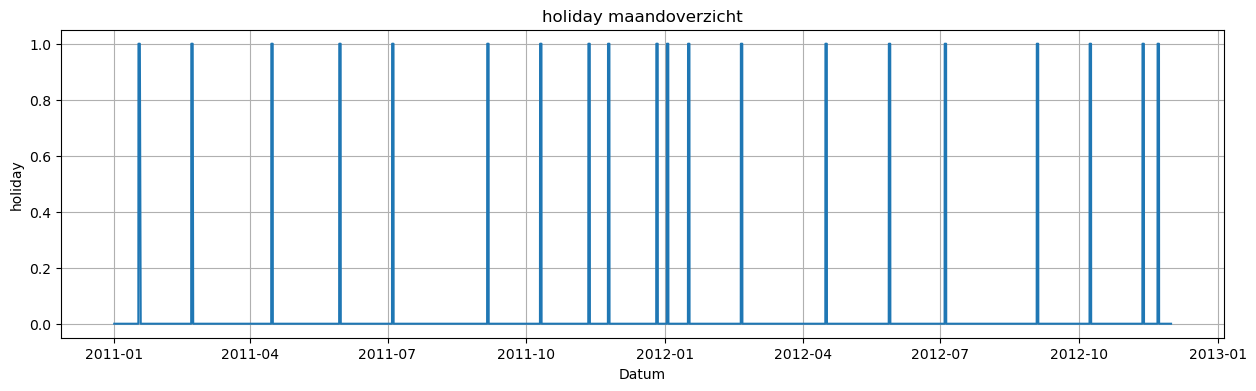

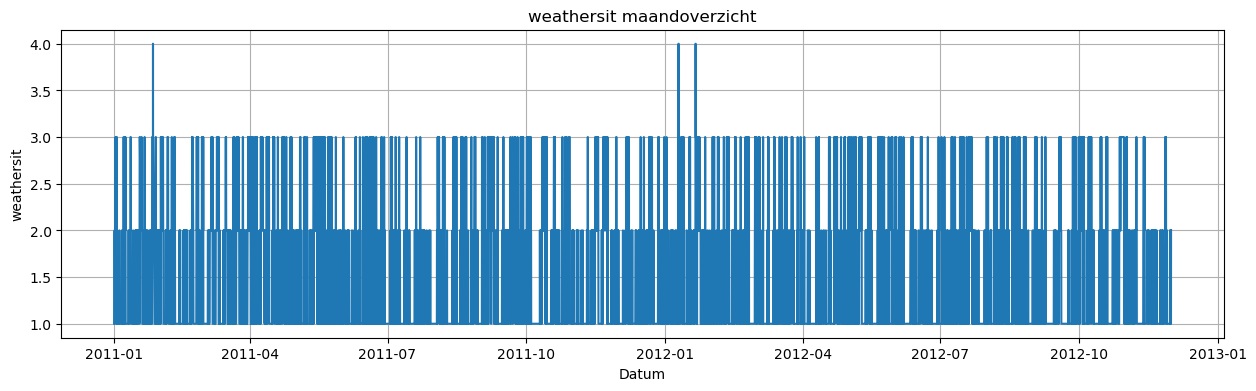

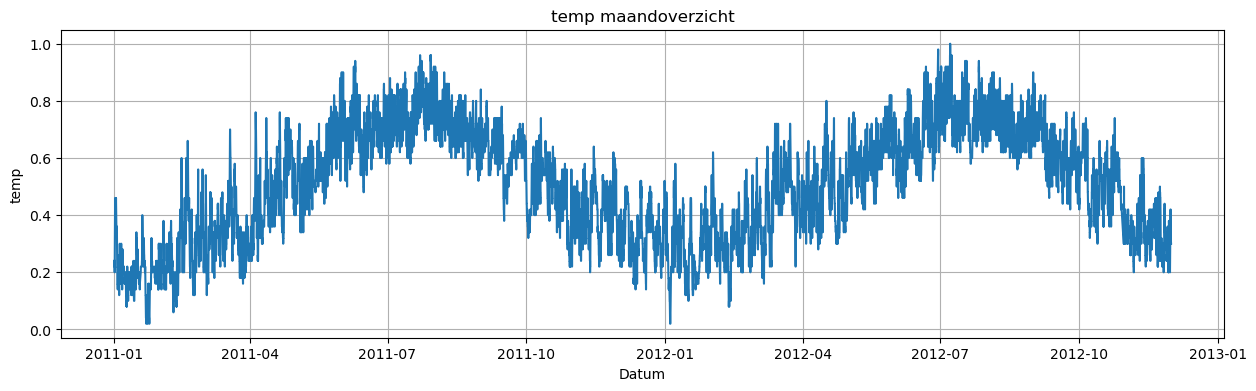

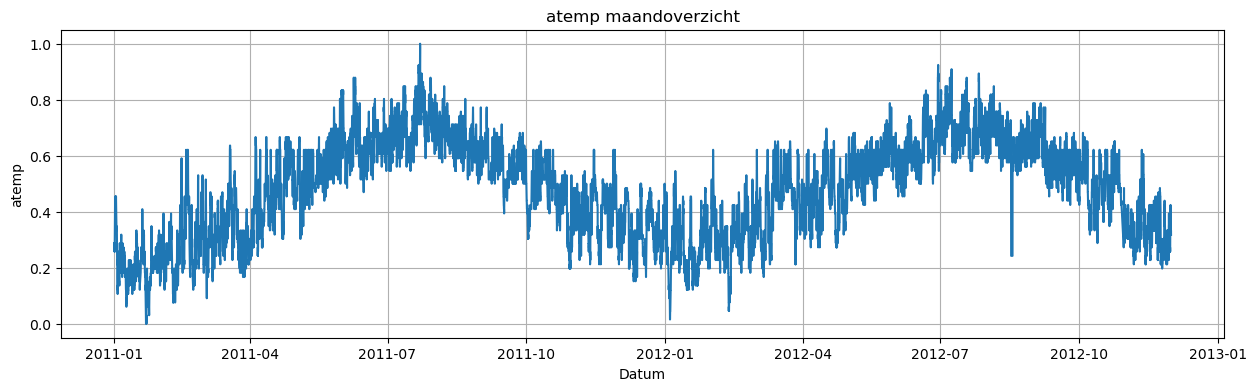

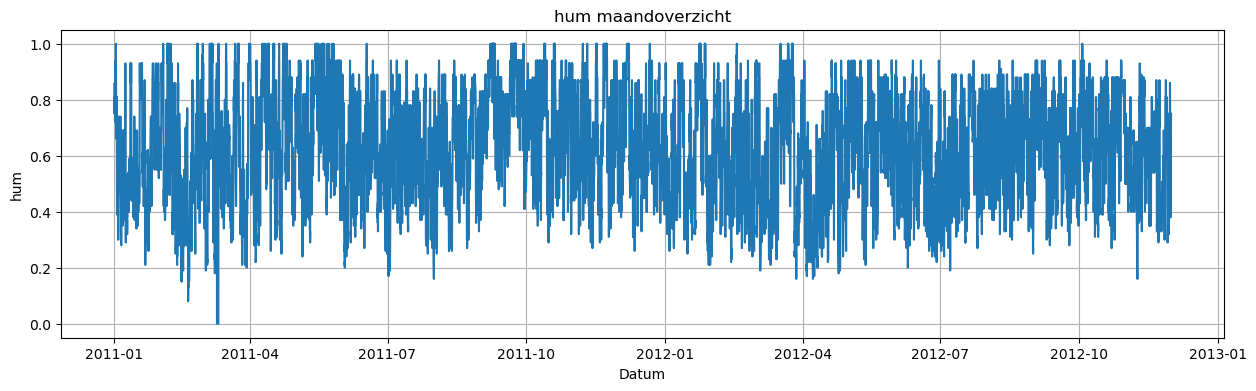

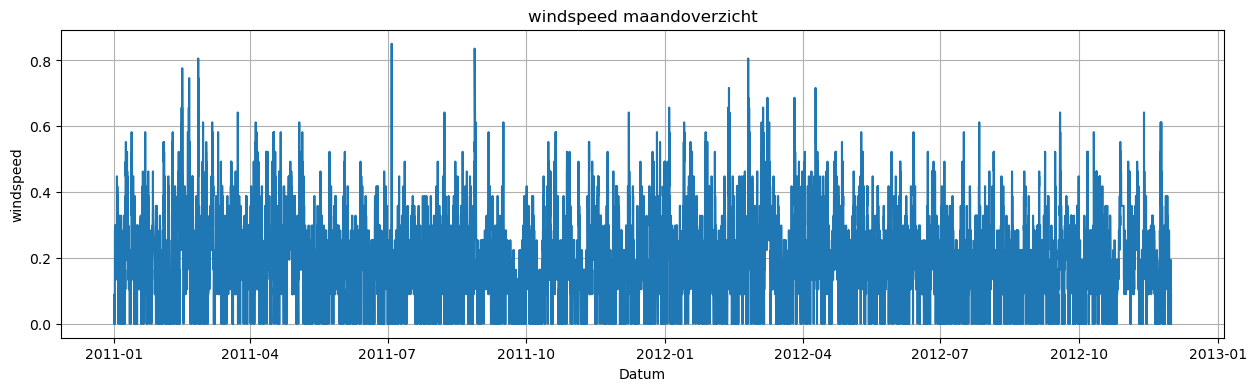

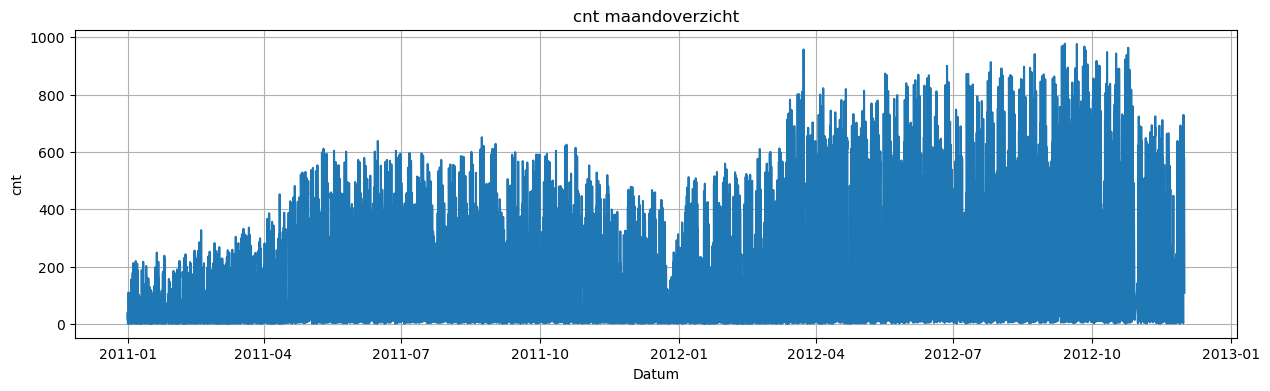

In [39]:
columns = ['holiday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']

for column in columns:
    plt.figure(figsize=(15, 4))
    plt.plot(df.index, df[column])
    plt.title(f'{column} maandoverzicht')
    plt.xlabel('Datum')
    plt.ylabel(column)
    plt.grid(True)
    plt.show()

## 1.3. Correlaties berekenen

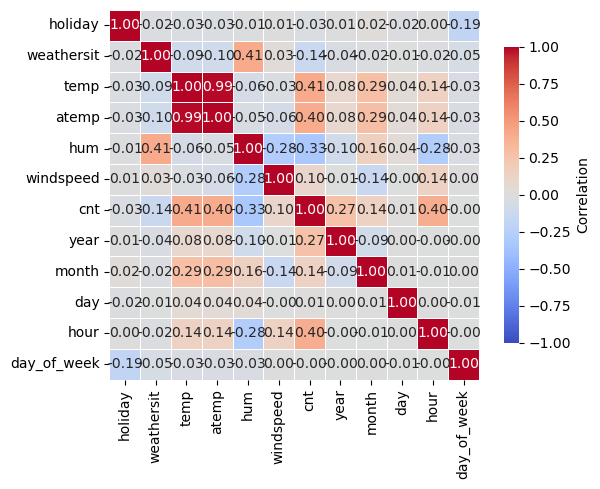

In [45]:
correlations = df.corr()

sns.heatmap(
    correlations,
    annot=True,
    cmap='coolwarm',
    fmt='.2f', 
    linewidths=0.5,
    linecolor='white',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={'shrink': 0.8, 'label': 'Correlation'}
)
plt.show()

# 1.4 Belangrijkste bevindingen EDA

**Visualisaties**
- **Holiday:** Er lijkt geen trend te zijn bij de holiday.
- **Weathersit:** Het is niet direct duidelijk wat voor mogelijke seizoenscomponenten uit Weather situation te halen zijn.
- **Temp:** Er lijk zowel een jaarlijks als dagelijks patroon te zijn binnen de dataset. Dit zou mogelijk iets te maken kunnen hebben met winter & zomer en dag & nacht.
- **Atemp:** Net zoals de gemeten temperatuur zou de daadwerkelijke temperatuur oop een jaarlijks en dagelijks patroon hebben.
- **hum:** Er lijken meerdere seizoenscomponenten te zijn. Dit zou verder onderzocht kunnen worden met behulp van de Fourier Transform.
- **windspeed:** Het is niet direct duidelijk of er een seizoenscomponent is. Dit zou verder onderzocht kunnen worden met behulp van de Fourier Transform.
- **cnt:** Er lijkt een algemene stijgende trend te zijn. Er is mogelijk een frequentie van 4 maanden aanwezig, maar dit zou pas later getest kunnen worden met de Fourier Transform.

**correlaties**
- cnt lijkt het meest te correleren met uur van de dag en temperatuur. Ondanks dit zou het handig zijn om bij het trainen van het model toch alle features mee te nemen.
- temperatuur is natuurlijk heel hoog gecorreleerd met actual temperatuur, daarom zou één van deze kolommen weg kunnen bij de voorspellingen. temp heeft net een hogere correlatie, dus atemp zal weggelaten worden.